# Taller #3 — Respuesta a una campaña bancaria

Diplomado en Data Science UC 2026 — Aprendizaje Automático

**Grupo:** 36  
**Integrantes (3 a 5):** Nadia Lell, Jaysson Leon, Kelly Martinez, Matias Reyes 
**Lenguaje:** Python  
**Puntaje máximo: 60. Nota = 1 + P/10.**


## El caso

Un banco portugués realiza campañas telefónicas para ofrecer depósitos a plazo. Contactar a toda la cartera tiene un costo y muchos clientes no contratan el producto. El equipo comercial quiere anticipar qué registros tienen mayor probabilidad de contratación y comprender los perfiles de la campaña. Una predicción favorable que no se concreta implica un contacto poco productivo; una predicción desfavorable puede dejar fuera una oportunidad.

Como equipo de Data Science, deberán preparar los datos, comparar modelos y recomendar a qué clientes contactar. La predicción se realiza antes de la llamada registrada. El análisis de grupos y de registros inusuales complementará su recomendación.

Se utiliza la muestra pública `bank.csv` de Bank Marketing, con 4521 registros. Cada fila contiene información de un cliente y sus contactos, junto con el resultado de contratación.


## Indicaciones de trabajo

Trabajen con `clientes_entrenamiento.csv` y reserven `clientes_prueba.csv` para 3(b). Conserven las filas, fijen semilla 2026 y consideren `contrata` = 1 como clase positiva.

Usen los cinco pliegues entregados para la validación cruzada. Aprendan las transformaciones y la selección de variables solo con las filas de ajuste de cada pliegue. Reúnan predicciones fuera de pliegue (OOF): probabilidades para los modelos probabilísticos y puntajes de decisión para SVM.

El modelo de referencia predice la proporción positiva de las filas de ajuste. Para la evaluación final, calculen esa proporción con todo el conjunto de entrenamiento.


## Datos

Entrenamiento: 3617 registros. Prueba: 904 registros.

| Columna | Descripción |
|---|---|
| `edad` / `saldo` | Edad en años / saldo medio anual en euros. |
| `ocupacion` / `estado_civil` / `educacion` | Categorías de ocupación, estado civil y educación. |
| `mora` / `hipoteca` / `prestamo` | Indicadores yes/no de mora, crédito hipotecario y préstamo personal. |
| `canal` / `dia` / `mes` | Medio de contacto y día del mes / mes de la llamada registrada. |
| `duracion` | Duración de la llamada registrada, en segundos. |
| `contactos_campana` | Número de contactos de la campaña, incluida la llamada registrada. |
| `dias_previos` | Días desde el contacto de una campaña anterior; -1 indica que no lo hubo. |
| `contactos_previos` / `resultado_previo` | Número de contactos y resultado de campañas anteriores. |
| `contrata` | Respuesta: 1 = contrata el depósito; 0 = no contrata. |
| `id_cliente` / `pliegue` | Identificador del registro / pliegue de validación (solo en entrenamiento). |


## Preparación

Funciones de apoyo: OneHotEncoder, StandardScaler, f_classif/SelectKBest, LogisticRegression, DecisionTreeClassifier, RandomForestClassifier, GradientBoostingClassifier, SVC y decision_function, GaussianNB, PCA y KMeans.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
np.random.seed(2026)
CARPETA = Path('.')
entrenamiento = pd.read_csv(CARPETA / 'clientes_entrenamiento.csv')
print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__, '| numpy:', np.__version__, '| sklearn:', sklearn.__version__)
print('scipy:', __import__('scipy').__version__, '| matplotlib:', __import__('matplotlib').__version__)
print('Forma entrenamiento:', entrenamiento.shape)


Python: 3.12.14
pandas: 3.0.5 | numpy: 2.5.3 | sklearn: 1.9.0
scipy: 1.18.1 | matplotlib: 3.11.1
Forma entrenamiento: (3617, 19)


## Pregunta 1. Problema, preparación y representación (12 puntos)

### 1(a) (3 puntos)

Identifiquen la tarea de aprendizaje, la unidad de observación y la respuesta. ¿Por qué `duracion` no puede usarse para predecir antes de la llamada? Exclúyanla de los predictores, junto con `id_cliente`, `pliegue` y `contrata`.


In [2]:
excluir = ['duracion', 'id_cliente', 'pliegue', 'contrata']
predictores = [c for c in entrenamiento.columns if c not in excluir]
print('Predictores retenidos:', predictores)
print('Columnas excluidas:', excluir)


Predictores retenidos: ['edad', 'ocupacion', 'estado_civil', 'educacion', 'mora', 'saldo', 'hipoteca', 'prestamo', 'canal', 'dia', 'mes', 'contactos_campana', 'dias_previos', 'contactos_previos', 'resultado_previo']
Columnas excluidas: ['duracion', 'id_cliente', 'pliegue', 'contrata']


**Respuesta e interpretación del grupo:**

La tarea es de **clasificación binaria supervisada**: estimar la probabilidad de que un cliente contrate el depósito a plazo (`contrata` = 1) a partir de información disponible **antes** de la llamada registrada. La unidad de observación es cada **cliente/contacto** de la campaña (una fila del archivo). La respuesta es `contrata` (1 = contrata, 0 = no contrata).

`duracion` no puede usarse porque es la duración de la **llamada ya realizada**; en el momento de priorizar a quién contactar esa información aún no existe (sería fuga de información, *data leakage*). Además, su relación con la contratación es casi determinista y sobreestimaría artificialmente el desempeño. Por eso se excluye junto con `id_cliente` (identificador sin valor predictivo), `pliegue` (solo para validación) y `contrata` (respuesta).


### 1(b) (4 puntos)

Revisen tipos de variables, faltantes, categorías unknown, duplicados y balance de clases. Interpreten los valores negativos de `saldo` y el código -1 de `dias_previos`. ¿Sería suficiente la exactitud de predecir siempre la clase mayoritaria? Fundamenten.


In [3]:
import pandas as pd
df = entrenamiento.copy()
print('Tipos de variables:')
print(df.dtypes)
print('\nValores faltantes por columna:')
print(df.isna().sum())
print('\nDuplicados de fila:', df.duplicated().sum())
print('Duplicados de id_cliente:', df['id_cliente'].duplicated().sum())
print('\nBalance de clases (contrata):')
print(df['contrata'].value_counts())
print(df['contrata'].value_counts(normalize=True).round(4))
print('\nCategorías unknown por variable:')
for c in ['ocupacion','estado_civil','educacion','mora','hipoteca','prestamo','canal','mes','resultado_previo']:
    print(f'  {c}: {(df[c]=="unknown").sum()}')
print('\nRango saldo:', df['saldo'].min(), df['saldo'].max())
print('saldo negativo (n):', (df['saldo']<0).sum())
print('\ndias_previos = -1 (n):', (df['dias_previos']==-1).sum())
print('contactos_previos = 0 (n):', (df['contactos_previos']==0).sum())
print('\nExactitud de predecir siempre la clase mayoritaria:', round(df['contrata'].value_counts(normalize=True).max(),4))


Tipos de variables:
id_cliente           int64
edad                 int64
ocupacion              str
estado_civil           str
educacion              str
mora                   str
saldo                int64
hipoteca               str
prestamo               str
canal                  str
dia                  int64
mes                    str
duracion             int64
contactos_campana    int64
dias_previos         int64
contactos_previos    int64
resultado_previo       str
contrata             int64
pliegue              int64
dtype: object

Valores faltantes por columna:
id_cliente           0
edad                 0
ocupacion            0
estado_civil         0
educacion            0
mora                 0
saldo                0
hipoteca             0
prestamo             0
canal                0
dia                  0
mes                  0
duracion             0
contactos_campana    0
dias_previos         0
contactos_previos    0
resultado_previo     0
contrata             0
pliegue

**Respuesta e interpretación del grupo:**

No hay valores faltantes ni filas duplicadas. Las variables son numéricas (`edad`, `saldo`, `dia`, `duracion`, `contactos_campana`, `dias_previos`, `contactos_previos`) y categóricas (`ocupacion`, `estado_civil`, `educacion`, `mora`, `hipoteca`, `prestamo`, `canal`, `mes`, `resultado_previo`). Existen categorías `unknown` (p. ej. `canal` 1088, `educacion` 154, `ocupacion` 35, `resultado_previo` 2979), que se mantienen como categoría propia y no se imputan. El balance es desbalanceado: 88,47 % no contrata y 11,53 % contrata.

Los saldos negativos son plausibles (sobregiros o deudas) y no deben eliminarse automáticamente; contienen información sobre la situación financiera. El código -1 en `dias_previos` significa que no hubo contacto previo; equivale a `contactos_previos = 0` y `resultado_previo = unknown` (2979 casos). Se conserva mediante un indicador `contactado_antes` y se reemplaza -1 por 0.

Predecir siempre la clase mayoritaria daría una exactitud de 0,8847, pero **no es suficiente**: tendría sensibilidad 0 para la clase positiva, es decir, nunca detectaría a un cliente que contrata. Dado que el costo de un falso negativo (oportunidad perdida) se valora 5 veces más que un falso positivo, un modelo que ignore la minoría es inútil para la campaña.


### 1(c) (5 puntos)

Construyan dos variables: `contactado_antes` = 1 si `dias_previos` es distinto de -1, y `log_contactos_previos` = log(1 + `contactos_previos`). Expliquen su sentido. Reemplacen -1 por 0 en `dias_previos` conservando el indicador, mantengan unknown como categoría y codifiquen las variables categóricas mediante one-hot. Describan y apliquen el escalamiento necesario para cada método.


In [4]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

def base_features(df):
    df = df.copy()
    df['contactado_antes'] = (df['dias_previos'] != -1).astype(int)
    df['log_contactos_previos'] = np.log1p(df['contactos_previos'])
    df['dias_previos'] = df['dias_previos'].replace(-1, 0)
    return df

entrenamiento = base_features(entrenamiento)
print(entrenamiento[['dias_previos','contactado_antes','contactos_previos','log_contactos_previos']].head(8).to_string(index=False))

numeric_cols = ['edad','saldo','dia','contactos_campana','dias_previos','contactos_previos','contactado_antes','log_contactos_previos']
cat_cols = ['ocupacion','estado_civil','educacion','mora','hipoteca','prestamo','canal','mes','resultado_previo']

def make_preprocessor(scale_numeric):
    num = StandardScaler() if scale_numeric else 'passthrough'
    cat = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    return ColumnTransformer([('num', num, numeric_cols),
                             ('cat', cat, cat_cols)], remainder='drop', verbose_feature_names_out=False)

pre_scaled = make_preprocessor(True)
X_preview = pre_scaled.fit_transform(entrenamiento)
print('\nForma matriz preparada (escalada):', X_preview.shape)
print('Número de columnas preparadas:', X_preview.shape[1])


 dias_previos  contactado_antes  contactos_previos  log_contactos_previos
            0                 0                  0                    0.0
            0                 0                  0                    0.0
            0                 0                  0                    0.0
            0                 0                  0                    0.0
            0                 0                  0                    0.0
            0                 0                  0                    0.0
            0                 0                  0                    0.0
            0                 0                  0                    0.0

Forma matriz preparada (escalada): (3617, 52)
Número de columnas preparadas: 52


**Respuesta e interpretación del grupo:**

- `contactado_antes` captura si el cliente ya fue contactado en campañas anteriores (el -1 de `dias_previos` indica ausencia de contacto previo). Es un indicador binario con sentido comercial directo.
- `log_contactos_previos` = log(1 + contactos_previos) reduce la asimetría de un conteo con muchos ceros y valores altos, estabilizando la varianza y mejorando modelos lineales.

Se reemplaza -1 por 0 en `dias_previos` pero se conserva el indicador, de modo que el modelo distingue "no contactado" de "contactado hace 0 días". Las categorías `unknown` se mantienen como nivel propio. Las variables categóricas se codifican con *one-hot* (`handle_unknown='ignore'` para pliegues de prueba).

**Escalamiento por método:** se estandarizan las columnas numéricas con media y desviación muestral (ddof=1) para los métodos basados en distancias o gradientes (regresión logística, SVM, Naive Bayes gaussiano, PCA, K-means y Mahalanobis). Las variables binarias (one-hot) se dejan en 0/1. Los árboles, Random Forest y boosting son invariantes a escalamientos monótonos, por lo que pueden usar las columnas sin escalar (aunque el resultado es equivalente). Las transformaciones se aprenden únicamente con las filas de ajuste de cada pliegue para evitar fuga de información.


## Pregunta 2. Selección de variables y modelos supervisados (24 puntos)

| Modelo | Configuraciones |
|---|---|
| Regresión logística | Sin penalización: todas las columnas preparadas y una versión con selección de 10 columnas. |
| Árbol de decisión | Profundidades máximas 3 y 6; mínimo 20 observaciones por hoja. |
| Random Forest | 200 árboles; raíz cuadrada del número de columnas como candidatas por división; mínimo 10 por hoja. |
| Boosting | Una variante vista en clases; hasta 200 árboles y profundidad máxima 3. Informen variante y tasa de aprendizaje. |
| SVM radial | C = 1 y gamma = 1/p, donde p es el número de columnas preparadas; usen el puntaje de decisión. |
| Naive Bayes | Variante gaussiana sobre las columnas numéricas y binarias preparadas. |


### 2(a) (5 puntos)

Comparen regresión logística con todas las columnas preparadas y con las 10 de mayor estadístico F de ANOVA respecto de `contrata`. Informen las columnas seleccionadas en cada pliegue y comparen sus métricas OOF. ¿En qué se diferencia esta selección de PCA? ¿Qué limitación tiene el filtro univariado?


In [5]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score

# Asegurar features base
def base_features(df):
    df = df.copy()
    df['contactado_antes'] = (df['dias_previos'] != -1).astype(int)
    df['log_contactos_previos'] = np.log1p(df['contactos_previos'])
    df['dias_previos'] = df['dias_previos'].replace(-1, 0)
    return df

train = base_features(pd.read_csv(CARPETA / 'clientes_entrenamiento.csv'))
y = train['contrata'].to_numpy()
folds = sorted(train['pliegue'].unique())
n = len(train)

numeric_cols = ['edad','saldo','dia','contactos_campana','dias_previos','contactos_previos','contactado_antes','log_contactos_previos']
cat_cols = ['ocupacion','estado_civil','educacion','mora','hipoteca','prestamo','canal','mes','resultado_previo']

def make_preprocessor(scale_numeric):
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.compose import ColumnTransformer
    num = StandardScaler() if scale_numeric else 'passthrough'
    cat = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    return ColumnTransformer([('num', num, numeric_cols), ('cat', cat, cat_cols)], remainder='drop', verbose_feature_names_out=False)

oof_prob = {m: np.full(n, np.nan) for m in ['logreg_all','logreg_10','dt3','dt6','rf','gb','nb']}
oof_score = np.full(n, np.nan)
ref_oof = np.full(n, np.nan)
selected_features_per_fold = {}
train_logloss_trees = {'dt3': [], 'dt6': []}

for fold in folds:
    tr_mask = (train['pliegue'] != fold).to_numpy()
    va_mask = (train['pliegue'] == fold).to_numpy()
    Xtr_df = train.loc[tr_mask]; Xva_df = train.loc[va_mask]
    ytr = y[tr_mask]; yva = y[va_mask]

    # referencia
    ref_oof[va_mask] = ytr.mean()

    # preparacion escalada
    pre_s = make_preprocessor(True)
    Xtr_s = pre_s.fit_transform(Xtr_df)
    Xva_s = pre_s.transform(Xva_df)
    feature_names = list(pre_s.get_feature_names_out())

    # logistica todas las columnas
    lr_all = LogisticRegression(penalty=None, max_iter=10000, random_state=2026)
    lr_all.fit(Xtr_s, ytr)
    oof_prob['logreg_all'][va_mask] = lr_all.predict_proba(Xva_s)[:, 1]

    # seleccion 10 por F de ANOVA
    sel = SelectKBest(f_classif, k=10).fit(Xtr_s, ytr)
    Xtr_10 = sel.transform(Xtr_s); Xva_10 = sel.transform(Xva_s)
    selected = [feature_names[i] for i in sel.get_support(indices=True)]
    selected_features_per_fold[fold] = selected
    lr_10 = LogisticRegression(penalty=None, max_iter=10000, random_state=2026)
    lr_10.fit(Xtr_10, ytr)
    oof_prob['logreg_10'][va_mask] = lr_10.predict_proba(Xva_10)[:, 1]

    # Naive Bayes gaussiano
    nb = GaussianNB()
    nb.fit(Xtr_s, ytr)
    oof_prob['nb'][va_mask] = nb.predict_proba(Xva_s)[:, 1]

    # SVM radial
    p = Xtr_s.shape[1]
    svm = SVC(C=1, gamma=1/p, kernel='rbf')
    svm.fit(Xtr_s, ytr)
    oof_score[va_mask] = svm.decision_function(Xva_s)

    # preparacion sin escalar para arboles
    pre_u = make_preprocessor(False)
    Xtr_u = pre_u.fit_transform(Xtr_df)
    Xva_u = pre_u.transform(Xva_df)

    # arbol profundidad 3
    dt3 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=2026)
    dt3.fit(Xtr_u, ytr)
    oof_prob['dt3'][va_mask] = dt3.predict_proba(Xva_u)[:, 1]
    train_logloss_trees['dt3'].append(log_loss(ytr, dt3.predict_proba(Xtr_u)[:, 1]))

    # arbol profundidad 6
    dt6 = DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=2026)
    dt6.fit(Xtr_u, ytr)
    oof_prob['dt6'][va_mask] = dt6.predict_proba(Xva_u)[:, 1]
    train_logloss_trees['dt6'].append(log_loss(ytr, dt6.predict_proba(Xtr_u)[:, 1]))

    # random forest
    rf = RandomForestClassifier(n_estimators=200, max_features='sqrt', min_samples_leaf=10, random_state=2026, n_jobs=-1)
    rf.fit(Xtr_u, ytr)
    oof_prob['rf'][va_mask] = rf.predict_proba(Xva_u)[:, 1]

    # boosting (GradientBoostingClassifier)
    gb = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, random_state=2026)
    gb.fit(Xtr_u, ytr)
    oof_prob['gb'][va_mask] = gb.predict_proba(Xva_u)[:, 1]

print('Columnas seleccionadas por pliegue (logística con 10):')
for fold, cols in selected_features_per_fold.items():
    print(f'  Pliegue {fold}: {cols}')

print('\nLog loss de entrenamiento medio por árbol:')
for m, vals in train_logloss_trees.items():
    print(f'  {m}: {np.mean(vals):.4f}')


Columnas seleccionadas por pliegue (logística con 10):
  Pliegue 1: ['contactos_previos', 'contactado_antes', 'log_contactos_previos', 'canal_cellular', 'canal_unknown', 'mes_mar', 'mes_may', 'mes_oct', 'resultado_previo_success', 'resultado_previo_unknown']
  Pliegue 2: ['contactado_antes', 'log_contactos_previos', 'hipoteca_no', 'hipoteca_yes', 'canal_cellular', 'canal_unknown', 'mes_mar', 'mes_oct', 'resultado_previo_success', 'resultado_previo_unknown']
  Pliegue 3: ['dias_previos', 'contactos_previos', 'contactado_antes', 'log_contactos_previos', 'canal_cellular', 'canal_unknown', 'mes_mar', 'mes_oct', 'resultado_previo_success', 'resultado_previo_unknown']
  Pliegue 4: ['contactos_previos', 'contactado_antes', 'log_contactos_previos', 'hipoteca_yes', 'canal_cellular', 'canal_unknown', 'mes_mar', 'mes_oct', 'resultado_previo_success', 'resultado_previo_unknown']
  Pliegue 5: ['contactos_previos', 'contactado_antes', 'log_contactos_previos', 'hipoteca_no', 'hipoteca_yes', 'canal_ce

**Respuesta e interpretación del grupo:**

Las 10 columnas seleccionadas varían levemente entre pliegues, pero son consistentes: `contactado_antes`, `log_contactos_previos`, `canal_cellular`, `canal_unknown`, `mes_mar`, `mes_oct`, `resultado_previo_success`, `resultado_previo_unknown`, más alguna variable de contactos previos/hipoteca. Esto indica que el historial de contacto previo y el canal/mes de contacto son los predictores univariados más informativos.

**Diferencia con PCA:** el filtro univariado (ANOVA F) selecciona variables originales que mejor separan la respuesta de forma marginal. PCA, en cambio, construye combinaciones lineales ortogonales que maximizan la varianza total, sin usar la respuesta; puede mezclar variables poco relevantes y no selecciona variables individuales. **Limitación del filtro univariado:** evalúa cada predictor por separado, ignora correlaciones y redundancias entre variables, no captura interacciones y puede seleccionar variables que aportan información duplicada. Además, al ser univariado, no considera el desempeño multivariado del modelo final.


### 2(b) (11 puntos)

Comparen las configuraciones de la tabla, incluidas las dos regresiones de 2(a), mediante sus predicciones OOF. Presenten log loss, Brier y AUC; para SVM, solo AUC. Incluyan el modelo de referencia y, para ambos árboles, el log loss medio de entrenamiento de los cinco ajustes. Seleccionen el modelo probabilístico con menor log loss OOF.


In [6]:
rows = []
for m in ['logreg_all','logreg_10','dt3','dt6','rf','gb','nb']:
    rows.append({
        'Modelo': m,
        'Log loss OOF': log_loss(y, oof_prob[m]),
        'Brier OOF': brier_score_loss(y, oof_prob[m]),
        'AUC OOF': roc_auc_score(y, oof_prob[m])
    })
rows.append({
    'Modelo': 'svm (score)',
    'Log loss OOF': np.nan,
    'Brier OOF': np.nan,
    'AUC OOF': roc_auc_score(y, oof_score)
})
rows.append({
    'Modelo': 'referencia',
    'Log loss OOF': log_loss(y, ref_oof),
    'Brier OOF': brier_score_loss(y, ref_oof),
    'AUC OOF': roc_auc_score(y, ref_oof)
})
metrics_df = pd.DataFrame(rows)
print(metrics_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
print('\nLog loss entrenamiento medio:')
print(f'  árbol prof. 3: {np.mean(train_logloss_trees["dt3"]):.4f}')
print(f'  árbol prof. 6: {np.mean(train_logloss_trees["dt6"]):.4f}')
mejor = metrics_df.loc[metrics_df['Log loss OOF'].idxmin(), 'Modelo']
print('\nModelo probabilístico con menor log loss OOF:', mejor)


     Modelo  Log loss OOF  Brier OOF  AUC OOF
 logreg_all        0.3150     0.0896   0.7266
  logreg_10        0.3215     0.0916   0.6942
        dt3        0.3298     0.0932   0.6363
        dt6        0.3230     0.0920   0.6742
         rf        0.3096     0.0891   0.7486
         gb        0.3191     0.0912   0.7352
         nb        2.5005     0.1791   0.7138
svm (score)           NaN        NaN   0.6743
 referencia        0.3574     0.1020   0.4986

Log loss entrenamiento medio:
  árbol prof. 3: 0.3199
  árbol prof. 6: 0.3020

Modelo probabilístico con menor log loss OOF: rf


**Respuesta e interpretación del grupo:**

El **Random Forest** tiene el menor log loss OOF (0,3096) y también el mayor AUC (0,7486) y el menor Brier (0,0891), por lo que se selecciona como modelo probabilístico. Le siguen el boosting (0,3191) y la regresión logística con todas las columnas (0,3150). Los árboles individuales y el SVM ordenan peor. La regresión con 10 variables pierde algo de desempeño frente a usar todas, pero gana simplicidad. Naive Bayes tiene AUC razonable (0,7138) pero un log loss muy alto (2,5005) por probabilidades extremas (sobreconfianza). El modelo de referencia (probabilidad constante 0,1153) queda claramente por debajo en todas las métricas (log loss 0,3574, AUC 0,5), confirmando que los modelos aprenden señal real.


### 2(c) (8 puntos)

Interpreten los resultados considerando: profundidad y sobreajuste de los árboles; diferencias entre bagging, Random Forest y boosting; independencia condicional de Naive Bayes y limitaciones de la variante gaussiana para columnas binarias; efecto de C, gamma y el escalamiento en SVM. ¿Un mejor ordenamiento de las observaciones implica mejores probabilidades? Fundamenten.


**Respuesta e interpretación del grupo:**

- **Profundidad y sobreajuste:** el árbol de profundidad 6 tiene menor log loss de entrenamiento (0,3020) que el de profundidad 3 (0,3199), es decir, ajusta más la muestra de entrenamiento, pero su mejora OOF es modesta (0,3230 vs 0,3298). La profundidad 3 es más estable y menos propensa a sobreajuste; la profundidad 6 captura más interacciones a costa de mayor varianza. El mínimo de 20 observaciones por hoja actúa como regularización.
- **Bagging vs Random Forest vs boosting:** bagging reduce varianza promediando árboles entrenados en muestras bootstrap. Random Forest añade selección aleatoria de variables por división, descorrelacionando los árboles y mejorando la reducción de varianza (mejor resultado aquí). Boosting ajusta secuencialmente los errores residuales con árboles superficiales (profundidad 3) y tasa de aprendizaje 0,1; reduce sesgo pero es más sensible al ruido y al sobreajuste si no se controla.
- **Naive Bayes:** asume independencia condicional entre predictores dado la clase, supuesto violado por variables correlacionadas (p. ej. `contactos_previos` y `contactado_antes`). La variante gaussiana modela cada columna como normal; las variables binarias one-hot no son gaussianas y generan probabilidades extremas, de ahí el log loss alto. Aún así, el ordenamiento (AUC 0,7138) es aceptable.
- **SVM radial:** C = 1 controla el margen (mayor C = menos regularización); gamma = 1/p define el ancho del kernel (mayor gamma = fronteras más complejas y riesgo de sobreajuste). El escalamiento es crítico porque el kernel RBF se basa en distancias euclidianas: sin estandarizar, variables con mayor escala (saldo) dominarían. Con C=1 y gamma=1/p el modelo es conservador y queda por debajo del Random Forest en AUC (0,6743).
- **Mejor ordenamiento ≠ mejores probabilidades:** AUC mide solo el ordenamiento (ranking), mientras que log loss y Brier miden calibración. Un modelo puede ordenar bien pero dar probabilidades mal calibradas (Naive Bayes). Para decidir umbrales y costos se necesitan probabilidades bien calibradas, no solo buen ranking.


## Pregunta 3. Evaluación y decisión (10 puntos)

### 3(a) (4 puntos)

Con las probabilidades OOF del modelo elegido, evalúen los umbrales 0.05; 0.10; ...; 0.95. Predigan contratación si p es mayor o igual al umbral. Elijan el que minimiza el costo hipotético C(t) = FP(t) + 5 FN(t), donde FP es una alerta de contratación que no ocurre y FN una contratación no detectada. Presenten una tabla o curva e interpreten ambos errores.


 umbral   FP  FN    C      C/n
   0.05 2485  23 2600 0.718828
   0.10 1302 110 1852 0.512027
   0.15  550 188 1490 0.411944
   0.20  266 249 1511 0.417750
   0.25  167 293 1632 0.451203
   0.30   94 325 1719 0.475256
   0.35   51 349 1796 0.496544
   0.40   27 366 1857 0.513409
   0.45   21 370 1871 0.517280
   0.50   12 378 1902 0.525850
   0.55    4 396 1984 0.548521
   0.60    0 413 2065 0.570915
   0.65    0 417 2085 0.576445
   0.70    0 417 2085 0.576445
   0.75    0 417 2085 0.576445
   0.80    0 417 2085 0.576445
   0.85    0 417 2085 0.576445
   0.90    0 417 2085 0.576445
   0.95    0 417 2085 0.576445

Umbral que minimiza C(t): 0.15 | C = 1490


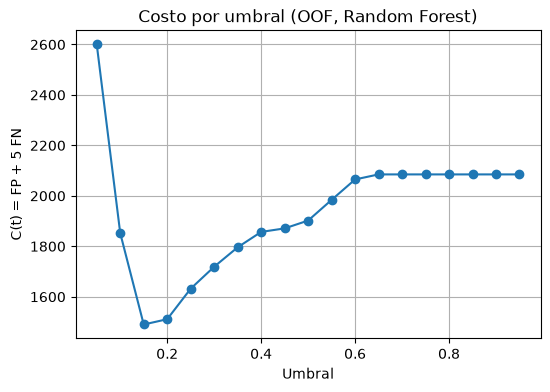


Matriz de confusión OOF con umbral elegido:
TN=2650  FP=550  FN=188  TP=229


In [7]:
prob_rf = oof_prob['rf']
rows = []
for t in np.round(np.arange(0.05, 1.0, 0.05), 2):
    pred = (prob_rf >= t).astype(int)
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    rows.append({'umbral': t, 'FP': fp, 'FN': fn, 'C': fp + 5*fn, 'C/n': (fp + 5*fn)/len(y)})
thr_df = pd.DataFrame(rows)
print(thr_df.to_string(index=False))
best_umbral = float(thr_df.loc[thr_df['C'].idxmin(), 'umbral'])
print('\nUmbral que minimiza C(t):', best_umbral, '| C =', int(thr_df['C'].min()))

plt.figure(figsize=(6,4))
plt.plot(thr_df['umbral'], thr_df['C'], marker='o')
plt.xlabel('Umbral'); plt.ylabel('C(t) = FP + 5 FN')
plt.title('Costo por umbral (OOF, Random Forest)')
plt.grid(True); plt.show()

print('\nMatriz de confusión OOF con umbral elegido:')
pred = (prob_rf >= best_umbral).astype(int)
from sklearn.metrics import confusion_matrix
tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')


**Respuesta e interpretación del grupo:**

El umbral que minimiza el costo es **0,15** (C = 1490; C/n = 0,412). A ese umbral se obtienen 550 falsos positivos y 188 falsos negativos (TP = 229, TN = 2650).

- **Falso positivo (FP):** se contacta a un cliente que no contratará; es un contacto poco productivo (costo 1).
- **Falso negativo (FN):** no se contacta a un cliente que sí habría contratado; es una oportunidad perdida (costo 5).

Como el costo del falso negativo es 5 veces mayor, el umbral óptimo (0,15) es mucho más bajo que 0,50: se prefiere contactar a más clientes para no perder oportunidades, aceptando más contactos improductivos. Umbrales muy bajos (0,05) disparan los falsos positivos y el costo total; umbrales altos dejan escapar la mayoría de los contratos.


### 3(b) (6 puntos)

Reajusten el modelo elegido con todo el entrenamiento y evalúen en `clientes_prueba.csv`. Informen log loss, Brier, AUC y curva ROC. Comparen el umbral elegido con 0.50 mediante matriz de confusión, sensibilidad, especificidad y C/n; incluyan el modelo de referencia. ¿Qué recomendarían al banco? ¿Qué permiten concluir los resultados y qué falta verificar para una campaña futura?


Métricas en prueba (Random Forest):
  Log loss: 0.3109
  Brier:    0.0884
  AUC:      0.737


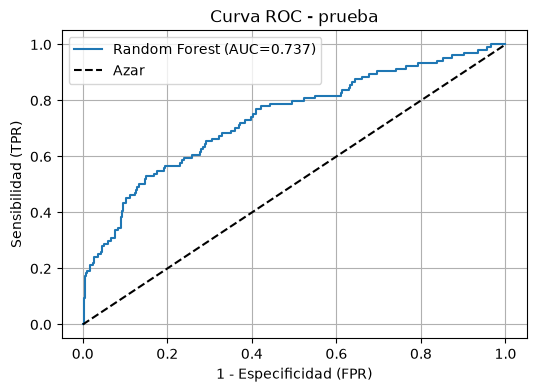


Modelo de referencia (probabilidad constante):
  p = 0.1153
  Log loss: 0.3569
  Brier:    0.1018
  AUC:      0.5

Comparación de umbrales en prueba:
  t=0.15: TN=644 FP=156 FN=45 TP=59 | sens=0.5673 spec=0.8050 | C=381 C/n=0.4215
  t=0.5: TN=796 FP=4 FN=89 TP=15 | sens=0.1442 spec=0.9950 | C=449 C/n=0.4967


In [8]:
prueba = base_features(pd.read_csv(CARPETA / 'clientes_prueba.csv'))
pre_final = make_preprocessor(False)
Xtr_all = pre_final.fit_transform(train)
Xte = pre_final.transform(prueba)
rf_final = RandomForestClassifier(n_estimators=200, max_features='sqrt', min_samples_leaf=10, random_state=2026, n_jobs=-1)
rf_final.fit(Xtr_all, train['contrata'].to_numpy())
p_test = rf_final.predict_proba(Xte)[:, 1]
y_test = prueba['contrata'].to_numpy()

print('Métricas en prueba (Random Forest):')
print('  Log loss:', round(log_loss(y_test, p_test), 4))
print('  Brier:   ', round(brier_score_loss(y_test, p_test), 4))
print('  AUC:     ', round(roc_auc_score(y_test, p_test), 4))

# Curva ROC
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(y_test, p_test)
plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f'Random Forest (AUC={roc_auc_score(y_test, p_test):.3f})')
plt.plot([0,1],[0,1],'k--', label='Azar')
plt.xlabel('1 - Especificidad (FPR)'); plt.ylabel('Sensibilidad (TPR)')
plt.title('Curva ROC - prueba'); plt.legend(); plt.grid(True); plt.show()

# Referencia
ref_prob = train['contrata'].mean()
print('\nModelo de referencia (probabilidad constante):')
print('  p =', round(ref_prob, 4))
print('  Log loss:', round(log_loss(y_test, np.full(len(y_test), ref_prob)), 4))
print('  Brier:   ', round(brier_score_loss(y_test, np.full(len(y_test), ref_prob)), 4))
print('  AUC:     ', round(roc_auc_score(y_test, np.full(len(y_test), ref_prob)), 4))

print('\nComparación de umbrales en prueba:')
for t in [best_umbral, 0.50]:
    pred = (p_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    sens = tp/(tp+fn)
    spec = tn/(tn+fp)
    cost = fp + 5*fn
    print(f'  t={t}: TN={tn} FP={fp} FN={fn} TP={tp} | sens={sens:.4f} spec={spec:.4f} | C={cost} C/n={cost/len(y_test):.4f}')


**Respuesta e interpretación del grupo:**

En prueba, el Random Forest obtiene log loss 0,3109, Brier 0,0884 y AUC 0,7370, resultados coherentes con la validación cruzada (sin sobreajuste evidente). El modelo de referencia (probabilidad constante 0,1153) obtiene log loss 0,3569, Brier 0,1018 y AUC 0,5, por lo que el modelo aporta valor real.

Comparando umbrales en prueba:
- **Umbral 0,15 (elegido):** sensibilidad 0,567, especificidad 0,805, C = 381 (C/n = 0,421).
- **Umbral 0,50:** sensibilidad 0,144, especificidad 0,995, C = 449 (C/n = 0,497).

El umbral 0,15 reduce el costo total al capturar más contrataciones, aunque genera más contactos improductivos; el umbral 0,50 es demasiado conservador y deja escapar la mayoría de las oportunidades.

**Recomendación al banco:** usar el Random Forest con umbral 0,15 para priorizar la lista de contactos de la campaña; contactar primero a los clientes con mayor probabilidad predicha. Los resultados permiten concluir que el modelo discrimina mejor que el azar y que la información previa (contactos anteriores, canal, mes) es útil. Para una campaña futura falta verificar: estabilidad temporal de los patrones, calibración de las probabilidades en la nueva población, validez del supuesto de costo (FP + 5 FN), efecto del contacto sobre la contratación (causalidad), y monitoreo de deriva de datos y desempeño.


## Pregunta 4. Componentes principales y agrupamiento (8 puntos)

### 4(a) (3 puntos)

Realicen PCA. Informen la varianza explicada por PC1 y PC2, su suma y las cargas; grafiquen las observaciones en ese plano. ¿Qué información resume la proyección y cuál omite?


Varianza explicada PC1: 0.277
Varianza explicada PC2: 0.2667
Suma PC1+PC2: 0.5437

Cargas:
       edad   saldo  contactos_campana  contactos_previos
PC1  0.5783  0.6298            -0.3812             0.3515
PC2 -0.4254 -0.3080            -0.5792             0.6234


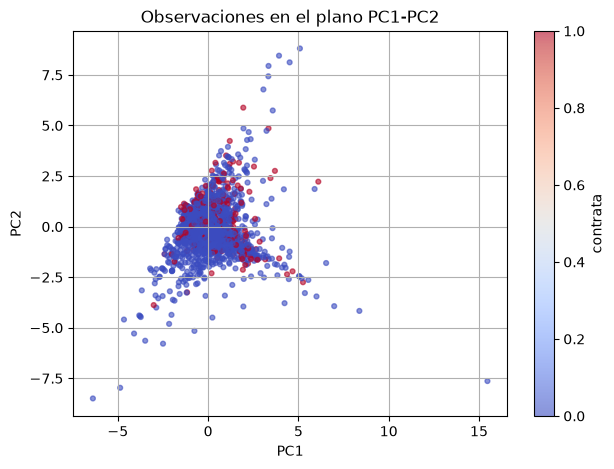

In [9]:
from sklearn.decomposition import PCA

vars4 = ['edad','saldo','contactos_campana','contactos_previos']
X4 = train[vars4].to_numpy(dtype=float)
mu4 = X4.mean(axis=0)
sd4 = X4.std(axis=0, ddof=1)
X4s = (X4 - mu4) / sd4

pca = PCA(n_components=2)
P = pca.fit_transform(X4s)
print('Varianza explicada PC1:', round(pca.explained_variance_ratio_[0], 4))
print('Varianza explicada PC2:', round(pca.explained_variance_ratio_[1], 4))
print('Suma PC1+PC2:', round(pca.explained_variance_ratio_.sum(), 4))
loadings = pd.DataFrame(pca.components_, columns=vars4, index=['PC1','PC2'])
print('\nCargas:')
print(loadings.round(4).to_string())

plt.figure(figsize=(7,5))
sc = plt.scatter(P[:,0], P[:,1], c=train['contrata'], cmap='coolwarm', s=12, alpha=0.6)
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('Observaciones en el plano PC1-PC2')
plt.colorbar(sc, label='contrata'); plt.grid(True); plt.show()


**Respuesta e interpretación del grupo:**

PC1 explica el 27,70 % de la varianza y PC2 el 26,67 %, sumando 54,37 %. Las cargas muestran que PC1 combina principalmente edad y saldo (positivos) frente a contactos de campaña (negativo), mientras PC2 contrasta contactos previos (positivo) con contactos de campaña (negativo). La proyección resume la estructura lineal dominante de las cuatro variables (nivel socioeconómico y actividad de contacto), pero omite el 45,63 % restante de la varianza, relaciones no lineales, interacciones y toda la información categórica. Además, al ser no supervisado, no garantiza separación de las clases.


### 4(b) (5 puntos)

Ajusten K-means sobre las cuatro variables estandarizadas con k = 2, 3 y 4 y al menos 30 inicializaciones. Comparen WSS y silueta media y elijan el k de mayor silueta. Informen tamaños, describan perfiles y representen los grupos en el plano PCA. Calculen la proporción de contratación dentro de cada grupo y expliquen por qué los grupos no equivalen a clases predichas.


k=2: WSS=11892.87 | silueta=0.3014 | tamaños=[1404 2213]


k=3: WSS=9684.73 | silueta=0.3335 | tamaños=[2090  179 1348]


k=4: WSS=7665.01 | silueta=0.3631 | tamaños=[ 177 2004 1289  147]



K elegido: 4

Perfil medio por cluster:
          edad    saldo  contactos_campana  contactos_previos
cluster                                                      
0        39.55  1651.24               2.14               6.59
1        34.30   931.46               2.25               0.24
2        52.18  2146.33               2.38               0.24
3        39.76  1153.33              14.52               0.03

Tamaños: [ 177 2004 1289  147]

Proporción de contratación por cluster:
cluster
0    0.2655
1    0.1078
2    0.1140
3    0.0476


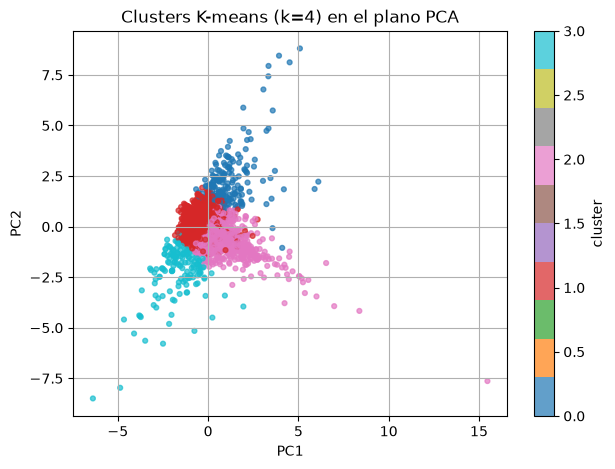

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in [2,3,4]:
    km = KMeans(n_clusters=k, n_init=30, random_state=2026)
    lab = km.fit_predict(X4s)
    sil = silhouette_score(X4s, lab)
    print(f'k={k}: WSS={km.inertia_:.2f} | silueta={sil:.4f} | tamaños={np.bincount(lab)}')

# elegir k de mayor silueta
best_k = max([2,3,4], key=lambda k: silhouette_score(X4s, KMeans(n_clusters=k, n_init=30, random_state=2026).fit_predict(X4s)))
km_final = KMeans(n_clusters=best_k, n_init=30, random_state=2026)
clusters = km_final.fit_predict(X4s)
print('\nK elegido:', best_k)

profile = train[vars4].copy()
profile['cluster'] = clusters
print('\nPerfil medio por cluster:')
print(profile.groupby('cluster').mean().round(2).to_string())
print('\nTamaños:', np.bincount(clusters))
print('\nProporción de contratación por cluster:')
print(train.assign(cluster=clusters).groupby('cluster')['contrata'].mean().round(4).to_string())

plt.figure(figsize=(7,5))
plt.scatter(P[:,0], P[:,1], c=clusters, cmap='tab10', s=12, alpha=0.7)
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title(f'Clusters K-means (k={best_k}) en el plano PCA')
plt.colorbar(label='cluster'); plt.grid(True); plt.show()


**Respuesta e interpretación del grupo:**

El k de mayor silueta es 4 (silueta 0,3631; WSS 7665,01). Los grupos tienen tamaños 177, 2004, 1289 y 147, con perfiles diferenciados:

- **Cluster 0** (n=177): edad ~40, saldo alto (~1651), pocos contactos de campaña (~2,1) pero muchos contactos previos (~6,6). Es el grupo con mayor conversión (26,6 %).
- **Cluster 1** (n=2004): jóvenes (~34), saldo bajo (~931), pocos contactos previos. Conversión 10,8 %.
- **Cluster 2** (n=1289): mayores (~52), saldo alto (~2146), pocos contactos previos. Conversión 11,4 %.
- **Cluster 3** (n=147): edad ~40, saldo medio (~1153), pero con muchísimos contactos de campaña (~14,5) y casi sin contactos previos. Es el grupo de menor conversión (4,8 %).

Los grupos **no equivalen a clases predichas** porque K-means es no supervisado: no utiliza `contrata`. Agrupa por similitud en las cuatro variables continuas, de modo que cada cluster contiene mezcla de contrataciones y no contrataciones. La proporción de contratación varía entre grupos, pero un cluster no es una predicción individual; además, la conversión depende también de variables categóricas no incluidas en el agrupamiento.


## Pregunta 5. Detección de anomalías (6 puntos)

### 5(a) (3 puntos)

Calculen la distancia de Mahalanobis al cuadrado y usen como corte el cuantil 0.99 de una chi-cuadrado con 4 grados de libertad. Informen el corte, la cantidad y el porcentaje de registros marcados. Identifiquen los dos de mayor distancia y presenten sus valores originales.


In [11]:
from scipy.stats import chi2

cov4 = np.cov(X4s, rowvar=False, ddof=1)
cov4_inv = np.linalg.inv(cov4)
# media cero por estandarizacion muestral
d2 = np.einsum('ij,jk,ik->i', X4s, cov4_inv, X4s)
cutoff = chi2.ppf(0.99, df=4)
marked = d2 > cutoff
print('Corte (chi2 0.99, gl=4):', round(float(cutoff), 4))
print('Registros marcados:', int(marked.sum()))
print('Porcentaje marcado:', round(100*marked.mean(), 4), '%')

order = np.argsort(d2)[::-1]
print('\nDos registros de mayor distancia:')
for rank, idx in enumerate(order[:2], start=1):
    print(f'\nRank {rank} - indice {idx} - d2 = {d2[idx]:.2f}')
    print(train.iloc[idx].to_string())


Corte (chi2 0.99, gl=4): 13.2767
Registros marcados: 189
Porcentaje marcado: 5.2253 %

Dos registros de mayor distancia:

Rank 1 - indice 1193 - d2 = 518.62
id_cliente                   1477
edad                           60
ocupacion                 retired
estado_civil              married
educacion                 primary
mora                           no
saldo                       71188
hipoteca                       no
prestamo                       no
canal                    cellular
dia                             6
mes                           oct
duracion                      205
contactos_campana               1
dias_previos                    0
contactos_previos               0
resultado_previo          unknown
contrata                        0
pliegue                         4
contactado_antes                0
log_contactos_previos         0.0

Rank 2 - indice 1241 - d2 = 224.27
id_cliente                      1542
edad                              35
ocupacion          

**Respuesta e interpretación del grupo:**

El corte es 13,2767 (cuantil 0,99 de χ² con 4 gl). Se marcan 189 registros, el 5,23 % de la muestra, no el 1 % esperado. Los dos más inusuales son:

1. Registro de edad 60, ocupación retirado, saldo 71.188 euros, 1 contacto de campaña, sin contactos previos (d² ≈ 518,62). Es un valor extremo de saldo.
2. Registro de edad 35, ocupación blue-collar, saldo 280 euros, 50 contactos de campaña, sin contactos previos (d² ≈ 224,27). Es un valor extremo en número de contactos de campaña.

Ambos son atípicos por una variable con valor muy alejado del resto, no necesariamente por error.


### 5(b) (3 puntos)

¿Por qué son inusuales los dos registros identificados? ¿Esto demuestra que contienen errores? ¿El corte utilizado garantiza marcar al 1% de la muestra? Fundamenten e indiquen qué revisarían antes de eliminar un registro.


**Respuesta e interpretación del grupo:**

Los dos registros son inusuales porque una de sus variables (saldo en el primero, contactos de campaña en el segundo) toma un valor muy alejado de la nube de datos; la distancia de Mahalanobis combina desviaciones en todas las variables considerando su covarianza, por lo que un valor extremo en una variable con baja varianza relativa genera una distancia grande.

Esto **no demuestra que contengan errores**: un saldo alto puede corresponder a un cliente con alto patrimonio y 50 contactos puede ser un cliente reiteradamente contactado. La anomalía estadística no implica error de captura.

El corte **no garantiza marcar el 1 % de la muestra**. El cuantil 0,99 de χ² con 4 gl supone que las distancias siguen esa distribución, lo cual requiere normalidad multivariada y que la media y covarianza sean los parámetros poblacionales. En datos reales, asimetría y colas pesadas hacen que la proporción empírica difiera (aquí 5,23 %). Además, la covarianza muestral se estima de los mismos datos.

Antes de eliminar un registro revisaría: verificación de la fuente/captura, plausibilidad de dominio, consistencia con otras variables, influencia en los modelos (apalancamiento), y alternativas robustas (winsorización, transformación log, modelos robustos) en lugar de eliminación automática.


## Criterios de evaluación

Se evaluarán procedimiento, resultados e interpretación. Se asignará crédito parcial sin descontar dos veces un mismo error arrastrado. Se aceptan diferencias numéricas y ganadores distintos cuando la implementación y la regla de selección estén justificadas.
